# BBBP: dataset inspection and molecular graphs

## A. Task and dataset

In [ ]:
import torch
import random
import numpy as np
import pandas as pd
from rdkit import Chem
from pathlib import Path
from torch_geometric.datasets import MoleculeNet
import matplotlib.pyplot as plt
from rdkit.Chem import Draw
from torch_geometric.utils.smiles import x_map, e_map
import networkx as nx
from torch_geometric.loader import DataLoader
from rdkit import DataStructs
from IPython.display import display
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import rdFingerprintGenerator
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.exceptions import ConvergenceWarning
import sklearn
import rdkit
import warnings
import copy
import json
import time
import torch.nn as nn
from torch_geometric.nn import GINEConv, global_mean_pool
from sklearn.metrics import (
    accuracy_score, confusion_matrix, roc_curve, precision_recall_curve, auc,
)
import joblib
import hashlib

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

In [ ]:
DATA_ROOT = Path("data/MoleculeNet")
dataset = MoleculeNet(
root=str(DATA_ROOT),
name="BBBP"
)
print(dataset)
print("Number of molecules:", len(dataset))
print("First graph:", dataset[0])

raw_df = pd.read_csv(DATA_ROOT / "bbbp" / "raw" / "BBBP.csv")
raw_mols = [Chem.MolFromSmiles(s) if isinstance(s, str) else None
            for s in raw_df["smiles"]]
raw_invalid = np.array([m is None for m in raw_mols])
raw_empty = np.array([m is not None and m.GetNumAtoms() == 0 for m in raw_mols])
raw_labels = pd.to_numeric(raw_df["p_np"], errors="coerce").to_numpy()
print("Source CSV records:", len(raw_df))
print("Source invalid SMILES:", int(raw_invalid.sum()))
print("Source valid but empty molecules:", int(raw_empty.sum()))
print("Source missing/non-finite labels:", int((~np.isfinite(raw_labels)).sum()))
print("Graphs returned by loader:", len(dataset))
print("Source-to-loader count difference:", len(raw_df) - len(dataset))


BBBP(2039)
Number of molecules: 2039
First graph: Data(x=[20, 9], edge_index=[2, 40], edge_attr=[40, 3], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1])
Source CSV records: 2050
Source invalid SMILES: 11
Source valid but empty molecules: 0
Source missing/non-finite labels: 0
Graphs returned by loader: 2039
Source-to-loader count difference: 11


[19:29:16] Explicit valence for atom # 1 N, 4, is greater than permitted
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] Explicit valence for atom # 6 N, 4, is greater than permitted
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] Explicit valence for atom # 6 N, 4, is greater than permitted
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] Explicit valence for atom # 11 N, 4, is greater than pe

In [24]:
graph = dataset[0]
print("Node-feature shape:", graph.x.shape)
print("Edge-index shape:", graph.edge_index.shape)
print("Edge-feature shape:", graph.edge_attr.shape)
print("Label:", graph.y)
print("SMILES:", graph.smiles)

Node-feature shape: torch.Size([20, 9])
Edge-index shape: torch.Size([2, 40])
Edge-feature shape: torch.Size([40, 3])
Label: tensor([[1.]])
SMILES: [Cl].CC(C)NCC(O)COc1cccc2ccccc12


In [25]:
rows = []
for i, g in enumerate(dataset):
    rows.append({
        "idx": i,
        "smiles": g.smiles,
        "label": g.y.view(-1)[0].item(),
        "num_nodes": g.num_nodes,
        "num_edges": g.edge_index.shape[1],
    })
df = pd.DataFrame(rows)

#Total size
print("Molecules returned by loader:", len(df))

# Missing and non-finite labels
finite_mask = np.isfinite(df["label"].values)
print("Missing or non-finite labels:", (~finite_mask).sum())

# Empty graphs 
empty_mask = df["num_nodes"] == 0
print("Empty graphs:", empty_mask.sum())

# Invalid SMILES 
df["mol_valid"] = df["smiles"].apply(lambda s: Chem.MolFromSmiles(s) is not None)
print("Invalid SMILES:", (~df["mol_valid"]).sum())

# Class counts and proportions for the finite labels 
valid_labels = df.loc[finite_mask, "label"]
counts = valid_labels.value_counts().sort_index()
props = valid_labels.value_counts(normalize=True).sort_index()
summary = pd.DataFrame({"count": counts, "proportion": props.round(4)})
summary.index.name = "label"
print("\nClass distribution (0 = non-penetrating, 1 = penetrating):")
print(summary)

assert counts.sum() == finite_mask.sum()
assert abs(props.sum() - 1.0) < 1e-9
print("\nPositive-class fraction:", round(props.get(1.0, 0), 4))
print(df[["num_nodes", "num_edges"]].describe())

Molecules returned by loader: 2039
Missing or non-finite labels: 0
Empty graphs: 0
Invalid SMILES: 0

Class distribution (0 = non-penetrating, 1 = penetrating):
       count  proportion
label                   
0.0      479      0.2349
1.0     1560      0.7651

Positive-class fraction: 0.7651
         num_nodes    num_edges
count  2039.000000  2039.000000
mean     24.064738    51.908779
std      10.591057    23.431304
min       2.000000     2.000000
25%      18.000000    38.000000
50%      23.000000    50.000000
75%      28.500000    62.000000
max     132.000000   290.000000


[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not r

In [ ]:
df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)
df["valid"] = df["mol"].notna()

n_loaded = len(df)
n_invalid = int((~df["valid"]).sum())
n_empty = int((df["num_nodes"] == 0).sum())

# Masks can overlap, count each removed record only once
bad_graph_mask = (~df["valid"]) | (df["num_nodes"] == 0)
bad_label_mask = ~np.isfinite(df["label"].to_numpy())
excluded_mask = bad_graph_mask | bad_label_mask
n_excluded = int(excluded_mask.sum())
work = df.loc[~excluded_mask].copy()
assert work["label"].isin([0.0, 1.0]).all(), "Unexpected non-binary label"
work["canon"] = work["mol"].apply(Chem.MolToSmiles)

# Duplicate analysis
grp = work.groupby("canon").agg(
    n_records=("idx", "size"),
    n_orig_smiles=("smiles", "nunique"),
    n_labels=("label", "nunique"),  
)
dup_groups = grp[grp["n_records"] > 1]
conflict_groups = grp[grp["n_labels"] > 1]

print("Canonical molecules appearing more than once:", len(dup_groups))
print("Extra (redundant) records they represent:", int((dup_groups["n_records"] - 1).sum()))
print("Duplicate groups with different original SMILES strings:", int((dup_groups["n_orig_smiles"] > 1).sum()))
print("Duplicate groups with consistent labels:", int((dup_groups["n_labels"] == 1).sum()))
print("Duplicate groups with conflicting labels:", len(conflict_groups))

# Cleaning rule 
conflict_set = set(conflict_groups.index)
removed_conflict = work[work["canon"].isin(conflict_set)]
kept = work[~work["canon"].isin(conflict_set)].drop_duplicates(subset="canon", keep="first")

n_removed_consistent_dups = len(work) - len(removed_conflict) - len(kept)

print("\n--- Cleaning summary ---")
print("Loaded records before cleaning:", n_loaded)
print("Removed invalid SMILES:", n_invalid)
print("Empty graphs:", n_empty)
print("Invalid-or-empty graph records (union):", int(bad_graph_mask.sum()))
print("Non-finite label records:", int(bad_label_mask.sum()))
print("Total excluded graph/label records (union):", n_excluded)
print("Removed records in conflicting-label groups:", len(removed_conflict),
      f"({len(conflict_groups)} groups)")
print("Removed redundant consistent duplicates:", n_removed_consistent_dups)
print("Final retained molecules:", len(kept))

assert kept["canon"].is_unique
assert n_loaded - n_excluded - len(removed_conflict) - n_removed_consistent_dups == len(kept)

clean_idx = kept["idx"].tolist()   
clean_df = kept.reset_index(drop=True)
print("\nClean class counts:\n", clean_df["label"].value_counts())
print(clean_df["label"].value_counts(normalize=True).round(4))

with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(removed_conflict[["idx", "smiles", "canon", "label"]].sort_values("canon"))

[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not removing hydrogen atom without neighbors
[19:29:16] WARNING: not r

Canonical molecules appearing more than once: 60
Extra (redundant) records they represent: 64
Duplicate groups with different original SMILES strings: 60
Duplicate groups with consistent labels: 50
Duplicate groups with conflicting labels: 10

--- Cleaning summary ---
Loaded records before cleaning: 2039
Removed invalid SMILES: 0
Empty graphs: 0
Invalid-or-empty graph records (union): 0
Non-finite label records: 0
Total excluded graph/label records (union): 0
Removed records in conflicting-label groups: 20 (10 groups)
Removed redundant consistent duplicates: 54
Final retained molecules: 1965

Clean class counts:
 label
1.0    1500
0.0     465
Name: count, dtype: int64
label
1.0    0.7634
0.0    0.2366
Name: proportion, dtype: float64


,idx,smiles,canon,label
98,98,CC(=O)Oc1ccccc1C(O)=O,CC(=O)Oc1ccccc1C(=O)O,0.0
996,996,C1=CC=CC(=C1C(O)=O)OC(C)=O,CC(=O)Oc1ccccc1C(=O)O,1.0
1323,1323,C1=CC(=CC2=C1C(C3=C(CC2)C=CC=N3)=C4CCN(C(OCC)=O)CC4)Cl,CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1,1.0
566,566,CCOC(=O)N1CCC(CC1)=C2c3ccc(Cl)cc3CCc4cccnc24,CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1,0.0
16,16,CN(C)C(=O)C(CCN1CCC(O)(CC1)c1ccc(Cl)cc1)(c1ccccc1)c1ccccc1,CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccccc1)c1ccccc1,1.0
547,547,CN(C)C(=O)C(CCN1CCC(O)(CC1)c2ccc(Cl)cc2)(c3ccccc3)c4ccccc4,CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccccc1)c1ccccc1,0.0
124,124,CN1C2CCC1CC(C2)OC(=O)C(CO)c3ccccc3,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2,0.0
1686,1686,C1=CC=CC=C1C(C(OC2CC3N(C)C(C2)CC3)=O)CO,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2,1.0
172,172,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC,0.0
1630,1630,C1=C3C(=C(C(=C1)CNC2=CC(=C(C(=C2)OC)OC)OC)C)C(=NC(=N3)N)N,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC,1.0


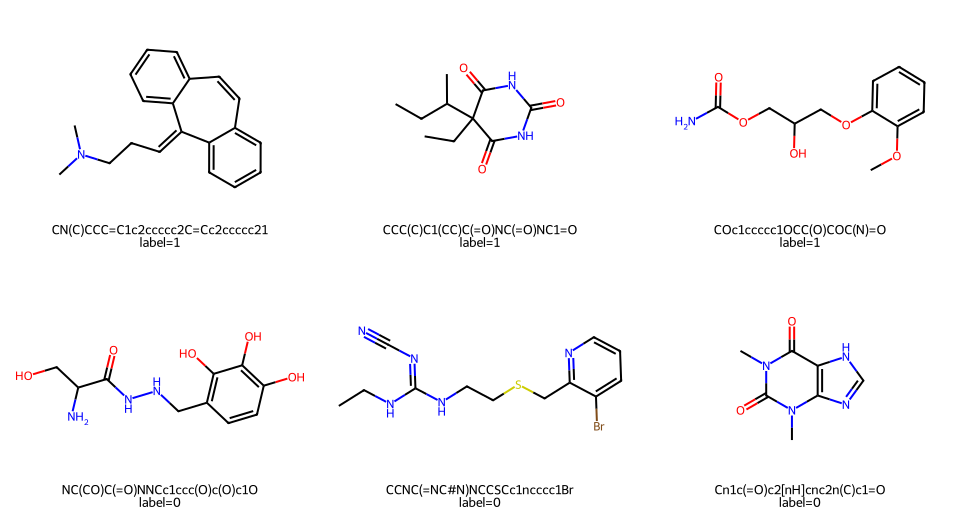

,idx,displayed_SMILES,label
1072,1121,CN(C)CCC=C1c2ccccc2C=Cc2ccccc21,1.0
476,497,CCC(C)C1(CC)C(=O)NC(=O)NC1=O,1.0
642,685,COc1ccccc1OCC(O)COC(N)=O,1.0
691,734,NC(CO)C(=O)NNCc1ccc(O)c(O)c1O,0.0
24,25,CCNC(=NC#N)NCCSCc1ncccc1Br,0.0
402,417,Cn1c(=O)c2[nH]cnc2n(C)c1=O,0.0


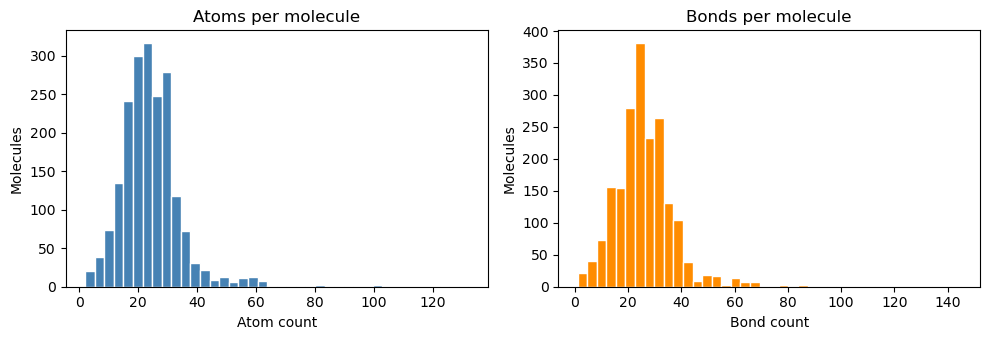

        num_nodes  num_bonds
mean        24.22      26.13
median      23.00      25.00
std         10.67      11.79
min          2.00       1.00
max        132.00     145.00
x.shape: torch.Size([20, 9])
edge_index.shape: torch.Size([2, 40])
edge_attr.shape: torch.Size([40, 3])
y: tensor([[1.]])
smiles: [Cl].CC(C)NCC(O)COc1cccc2ccccc12


In [27]:
short = clean_df[clean_df["canon"].str.len() <= 35]
picked = pd.concat([
    short[short["label"] == 1.0].sample(3, random_state=SEED),
    short[short["label"] == 0.0].sample(3, random_state=SEED),
])
mols = picked["mol"].tolist()
legends = [f"{s}\nlabel={int(l)}" for s, l in zip(picked["canon"], picked["label"])]

img = Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(320, 260), legends=legends)
display(img)
with pd.option_context("display.max_colwidth", None):
    display(picked[["idx", "canon", "label"]].rename(columns={"canon": "displayed_SMILES"}))

# Atom and bond count distribution
clean_df["num_bonds"] = clean_df["num_edges"] // 2 

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(clean_df["num_nodes"], bins=40, color="steelblue", edgecolor="white")
ax[0].set(title="Atoms per molecule", xlabel="Atom count", ylabel="Molecules")
ax[1].hist(clean_df["num_bonds"], bins=40, color="darkorange", edgecolor="white")
ax[1].set(title="Bonds per molecule", xlabel="Bond count", ylabel="Molecules")
plt.tight_layout()
plt.show()

print(clean_df[["num_nodes", "num_bonds"]].agg(["mean", "median", "std", "min", "max"]).round(2))

# Inspect one graph  
g = dataset[int(clean_df["idx"].iloc[0])]
print("x.shape:", g.x.shape)
print("edge_index.shape:", g.edge_index.shape)
print("edge_attr.shape:", g.edge_attr.shape)
print("y:", g.y)
print("smiles:", g.smiles)

## B. Graph representation and categorical features

In [28]:
print("Atom features (graph.x columns):")
for j, (name, vals) in enumerate(x_map.items()):
    print(f"  col {j}: {name:24s} {len(vals)} categories")

print("\nBond features (graph.edge_attr columns):")
for j, (name, vals) in enumerate(e_map.items()):
    print(f"  col {j}: {name:24s} {len(vals)} categories")

Atom features (graph.x columns):
  col 0: atomic_num               119 categories
  col 1: chirality                9 categories
  col 2: degree                   11 categories
  col 3: formal_charge            12 categories
  col 4: num_hs                   9 categories
  col 5: num_radical_electrons    5 categories
  col 6: hybridization            8 categories
  col 7: is_aromatic              2 categories
  col 8: is_in_ring               2 categories

Bond features (graph.edge_attr columns):
  col 0: bond_type                22 categories
  col 1: stereo                   6 categories
  col 2: is_conjugated            2 categories


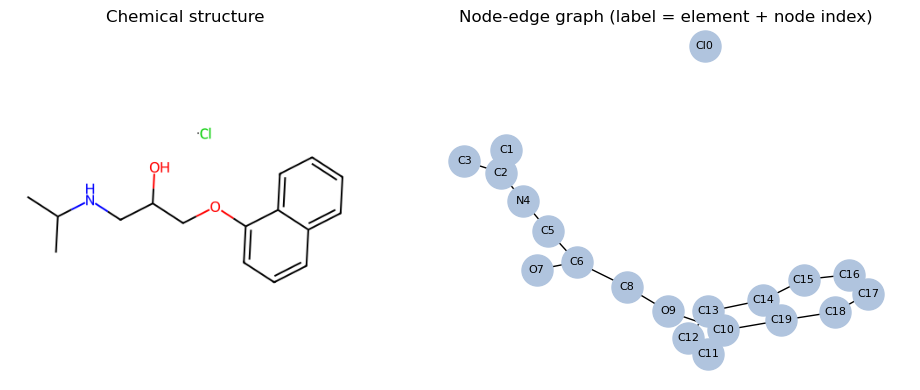

In [29]:
row = clean_df.iloc[0]
g = dataset[int(row["idx"])]
pt = Chem.GetPeriodicTable()

G = nx.Graph()
for i in range(g.num_nodes):
    G.add_node(i, sym=pt.GetElementSymbol(int(g.x[i, 0])))
for a, b in g.edge_index.t().tolist():
    if a < b:
        G.add_edge(a, b)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(Draw.MolToImage(row["mol"], size=(400, 400))); ax[0].axis("off")
ax[0].set_title("Chemical structure")
pos = nx.spring_layout(G, seed=SEED)
nx.draw(G, pos, ax=ax[1], labels={n: f"{d['sym']}{n}" for n, d in G.nodes(data=True)},
        node_color="lightsteelblue", node_size=500, font_size=8)
ax[1].set_title("Node-edge graph (label = element + node index)")
plt.tight_layout(); plt.show()

### Batching

In [30]:
clean_dataset = dataset[clean_idx]
loader = DataLoader(clean_dataset, batch_size=64, shuffle=False)

batch = next(iter(loader))
print(batch)
print("x:", batch.x.shape)
print("edge_index:", batch.edge_index.shape)
print("edge_attr:", batch.edge_attr.shape)
print("batch:", batch.batch.shape, "-> graphs in batch:", batch.num_graphs)
print("y:", batch.y.shape)

DataBatch(x=[1522, 9], edge_index=[2, 3276], edge_attr=[3276, 3], smiles=[64], y=[64, 1], batch=[1522], ptr=[65])
x: torch.Size([1522, 9])
edge_index: torch.Size([2, 3276])
edge_attr: torch.Size([3276, 3])
batch: torch.Size([1522]) -> graphs in batch: 64
y: torch.Size([64, 1])


In [31]:
all_y = torch.cat([d.y.view(-1) for d in clean_dataset])
assert torch.isfinite(all_y).all(), "non-finite labels"
assert all(d.num_nodes >= 1 for d in clean_dataset), "empty graph"
assert len(clean_dataset) == len(clean_idx)

n_graphs, n_labels, total_nodes = 0, 0, 0
for b in loader:
    assert b.y.view(-1).numel() == b.num_graphs, "label count != graph count"
    assert int(b.batch.max()) + 1 == b.num_graphs
    n_graphs += b.num_graphs
    n_labels += b.y.view(-1).numel()
    total_nodes += b.num_nodes
assert n_graphs == len(clean_dataset), "molecules lost in batching"
assert total_nodes == sum(d.num_nodes for d in clean_dataset)
print("All checks passed:", n_graphs, "graphs,", total_nodes, "atoms")

All checks passed: 1965 graphs, 47599 atoms


In [32]:
for name, vals in x_map.items():
    print(name, vals if len(vals) < 15 else f"{vals[:3]} ... {vals[-2:]}")
print()
for name, vals in e_map.items():
    print(name, vals)

atomic_num [0, 1, 2] ... [117, 118]
chirality ['CHI_UNSPECIFIED', 'CHI_TETRAHEDRAL_CW', 'CHI_TETRAHEDRAL_CCW', 'CHI_OTHER', 'CHI_TETRAHEDRAL', 'CHI_ALLENE', 'CHI_SQUAREPLANAR', 'CHI_TRIGONALBIPYRAMIDAL', 'CHI_OCTAHEDRAL']
degree [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
formal_charge [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6]
num_hs [0, 1, 2, 3, 4, 5, 6, 7, 8]
num_radical_electrons [0, 1, 2, 3, 4]
hybridization ['UNSPECIFIED', 'S', 'SP', 'SP2', 'SP3', 'SP3D', 'SP3D2', 'OTHER']
is_aromatic [False, True]
is_in_ring [False, True]

bond_type ['UNSPECIFIED', 'SINGLE', 'DOUBLE', 'TRIPLE', 'QUADRUPLE', 'QUINTUPLE', 'HEXTUPLE', 'ONEANDAHALF', 'TWOANDAHALF', 'THREEANDAHALF', 'FOURANDAHALF', 'FIVEANDAHALF', 'AROMATIC', 'IONIC', 'HYDROGEN', 'THREECENTER', 'DATIVEONE', 'DATIVE', 'DATIVEL', 'DATIVER', 'OTHER', 'ZERO']
stereo ['STEREONONE', 'STEREOANY', 'STEREOZ', 'STEREOE', 'STEREOCIS', 'STEREOTRANS']
is_conjugated [False, True]


### One-hot encoding for subsequent modeling

In [ ]:
# Encode columns on the cloned graphs, preserving dataset and raw codes
def one_hot_columns(values, category_map):
    assert values.shape[1] == len(category_map)
    parts = []
    for col, categories in enumerate(category_map.values()):
        codes = values[:, col].long()
        assert ((codes >= 0) & (codes < len(categories))).all()
        parts.append(F.one_hot(codes, num_classes=len(categories)))
    return torch.cat(parts, dim=1).float()

encoded_dataset = []
for original in clean_dataset:
    encoded = original.clone()
    encoded.x = one_hot_columns(original.x, x_map)
    encoded.edge_attr = one_hot_columns(original.edge_attr, e_map)
    assert encoded.x.shape == (original.num_nodes, sum(map(len, x_map.values())))
    assert encoded.edge_attr.shape == (original.num_edges, sum(map(len, e_map.values())))
    assert torch.equal(encoded.edge_index, original.edge_index)
    assert torch.equal(encoded.y, original.y)
    assert torch.all(encoded.x.sum(dim=1) == len(x_map))
    assert torch.all(encoded.edge_attr.sum(dim=1) == len(e_map))
    encoded_dataset.append(encoded)

encoded_loader = DataLoader(encoded_dataset, batch_size=64, shuffle=False)
encoded_batch = next(iter(encoded_loader))
print("One-hot atom width:", encoded_batch.x.shape[1])
print("One-hot bond width:", encoded_batch.edge_attr.shape[1])
print(encoded_batch)
assert sum(b.num_graphs for b in encoded_loader) == len(clean_dataset)


One-hot atom width: 177
One-hot bond width: 30
DataBatch(x=[1522, 177], edge_index=[2, 3276], edge_attr=[3276, 30], smiles=[64], y=[64, 1], batch=[1522], ptr=[65])


## C. Random and Bemis–Murcko scaffold splits

In [ ]:
labels = clean_df["label"].values.astype(int)

# positions in clean_df / encoded_dataset
pos = np.arange(len(clean_df))

rand_train, tmp = train_test_split(pos, test_size=0.30, stratify=labels, random_state=SEED)
rand_val, rand_test = train_test_split(tmp, test_size=0.50, stratify=labels[tmp], random_state=SEED)

In [ ]:
clean_df["scaffold"] = clean_df["mol"].apply(
    lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m, includeChirality=False)
)
groups = clean_df.groupby("scaffold").indices

sizes = pd.Series({s: len(ix) for s, ix in groups.items()}).sort_values(ascending=False)
print("Unique scaffolds:", len(groups))
print("Acyclic molecules (empty scaffold):", len(groups.get("", [])))
print("Largest scaffold groups:\n", sizes.head(8))
print("Singleton scaffolds:", int((sizes == 1).sum()))

Unique scaffolds: 1020
Acyclic molecules (empty scaffold): 95
Largest scaffold groups:
 c1ccccc1                           128
                                    95
O=C1C=CC2C(=C1)CCC1C3CCCC3CCC21     74
O=C1CN=C(c2ccccc2)c2ccccc2N1        26
O=C1C=C2CCC3C4CCCC4CCC3C2CC1        24
c1ccc2c(c1)Nc1ccccc1S2              22
c1ccc(Cc2ccccc2)cc1                 20
O=C1CC(=O)NC(=O)N1                  18
dtype: int64
Singleton scaffolds: 777


In [36]:
def check_and_report(name, tr, va, te, use_scaffold=False):
    n = len(clean_df)

    # coverage and disjointness of indices
    allidx = np.concatenate([tr, va, te])
    assert np.array_equal(np.sort(allidx), np.arange(n)), "missing, repeated, or out-of-range split indices"
    for a, b in [(tr, va), (tr, te), (va, te)]:
        assert not (set(a.tolist()) & set(b.tolist())), "index overlap"

    # canonical SMILES overlap
    canon = [set(clean_df["canon"].iloc[s]) for s in (tr, va, te)]
    assert not (canon[0] & canon[1]) and not (canon[0] & canon[2]) and not (canon[1] & canon[2]), \
        "canonical SMILES overlap"

    # scaffold disjointness (scaffold split only)
    if use_scaffold:
        sc = [set(clean_df["scaffold"].iloc[s]) for s in (tr, va, te)]
        assert not (sc[0] & sc[1]) and not (sc[0] & sc[2]) and not (sc[1] & sc[2]), \
            "scaffold overlap"

    rows = []
    for k, s in zip(["train", "val", "test"], (tr, va, te)):
        r = {"split": name, "subset": k, "n": len(s),
             "frac": round(len(s) / n, 3),
             "pos_rate": round(clean_df["label"].iloc[s].mean(), 4)}
        if use_scaffold:
            r["unique_scaffolds"] = clean_df["scaffold"].iloc[s].nunique()
        rows.append(r)
    print(f"{name}: all checks passed")
    return pd.DataFrame(rows)

rep_rand = check_and_report("random", rand_train, rand_val, rand_test)
display(rep_rand)

random: all checks passed


,split,subset,n,frac,pos_rate
0,random,train,1375,0.70,0.7636
1,random,val,295,0.15,0.7627
2,random,test,295,0.15,0.7627


In [37]:
def scaffold_split(groups, n_total, fracs=(0.70, 0.15, 0.15), seed=SEED):
    """Size-targeted scaffold split (not class-stratified). Every scaffold group goes entirely into one subset.
    groups: dict mapping scaffold SMILES -> array of positions in clean_df."""
    n_train, n_val = fracs[0] * n_total, fracs[1] * n_total
    rng = np.random.RandomState(seed)

    # sort by scaffold string first so the shuffle is reproducible
    sets = [np.asarray(ix) for _, ix in sorted(groups.items())]

    # Consider groups larger than half the validation target first; none qualify in this dataset.
    big = sorted([s for s in sets if len(s) > n_val / 2], key=len, reverse=True)
    small = [s for s in sets if len(s) <= n_val / 2]
    rng.shuffle(small)                      # seeded shuffle of the remaining groups

    tr, va, te = [], [], []
    for s in big + small:
        if len(tr) + len(s) <= n_train:
            tr.extend(s.tolist())
        elif len(va) + len(s) <= n_val:
            va.extend(s.tolist())
        else:
            te.extend(s.tolist())
    return np.array(sorted(tr)), np.array(sorted(va)), np.array(sorted(te))

scaf_train, scaf_val, scaf_test = scaffold_split(groups, len(clean_df))

rep_scaf = check_and_report("scaffold", scaf_train, scaf_val, scaf_test, use_scaffold=True)
display(rep_scaf)
display(rep_rand)

scaffold: all checks passed


,split,subset,n,frac,pos_rate,unique_scaffolds
0,scaffold,train,1375,0.700,0.7716,783
1,scaffold,val,294,0.150,0.8095,134
2,scaffold,test,296,0.151,0.6791,103


,split,subset,n,frac,pos_rate
0,random,train,1375,0.70,0.7636
1,random,val,295,0.15,0.7627
2,random,test,295,0.15,0.7627


In [38]:
for name, s in [("train", scaf_train), ("val", scaf_val), ("test", scaf_test)]:
    sc = clean_df["scaffold"].iloc[s]
    print(name,
          "| acyclic:", int((sc == "").sum()),
          "| benzene:", int((sc == "c1ccccc1").sum()),
          "| steroid-like:", int((sc == "O=C1C=CC2C(=C1)CCC1C3CCCC3CCC21").sum()))

train | acyclic: 95 | benzene: 0 | steroid-like: 0
val | acyclic: 0 | benzene: 0 | steroid-like: 74
test | acyclic: 0 | benzene: 128 | steroid-like: 0


In [39]:
np.savez("splits_seed42.npz", rand_train=rand_train, rand_val=rand_val, rand_test=rand_test,
         scaf_train=scaf_train, scaf_val=scaf_val, scaf_test=scaf_test)

## D. Non-neural Morgan fingerprint baseline

In [40]:
FP_RADIUS = 2
FP_SIZE = 2048
C_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]
THRESHOLD_GRID = np.round(np.arange(0.05, 0.951, 0.01), 2)

fp_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=FP_RADIUS, fpSize=FP_SIZE, includeChirality=False,
    useBondTypes=True, countSimulation=False,
)
# Rows align with clean_df and the existing split-position arrays.
X_fp = np.stack([
    fp_generator.GetFingerprintAsNumPy(mol) for mol in clean_df["mol"]
]).astype(np.float64)
y_fp = clean_df["label"].to_numpy(dtype=int)
assert X_fp.shape == (len(clean_df), FP_SIZE)
assert np.isin(X_fp, [0, 1]).all()
assert np.isin(y_fp, [0, 1]).all()

baseline_splits = {
    "random": {"train": rand_train, "val": rand_val, "test": rand_test},
    "scaffold": {"train": scaf_train, "val": scaf_val, "test": scaf_test},
}
print("Fingerprint matrix:", X_fp.shape)
print("Seed:", SEED, "| RDKit:", rdkit.__version__, "| scikit-learn:", sklearn.__version__)


Fingerprint matrix: (1965, 2048)
Seed: 42 | RDKit: 2026.09.1 | scikit-learn: 1.7.2


In [ ]:
baseline_models = {}
baseline_search_rows = []
baseline_selection_rows = []

for split_name, subsets in baseline_splits.items():
    tr = np.asarray(subsets["train"], dtype=int)
    va = np.asarray(subsets["val"], dtype=int)
    assert not set(tr) & set(va)
    assert np.unique(y_fp[tr]).size == 2, "Training needs both classes"
    assert np.unique(y_fp[va]).size == 2, "Validation ROC-AUC needs both classes"
    counts = np.bincount(y_fp[tr], minlength=2)
    train_weights = len(tr) / (2 * counts)
    best = None

    for c_value in C_GRID:
        model = LogisticRegression(
            C=c_value, penalty="l2", solver="liblinear",
            class_weight="balanced", max_iter=2000, tol=1e-4,
            random_state=SEED, fit_intercept=True,
        )
        # Do not select a model that did not converge
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            model.fit(X_fp[tr], y_fp[tr])
        assert model.classes_.tolist() == [0, 1]
        val_probability = model.predict_proba(X_fp[va])[:, 1]
        val_auc = roc_auc_score(y_fp[va], val_probability)
        baseline_search_rows.append({
            "split": split_name, "C": c_value, "val_roc_auc": val_auc,
            "iterations": int(model.n_iter_.max()),
        })
        # Ascending C grid and improvement implement the tie rule
        if best is None or val_auc > best["val_roc_auc"]:
            best = {"model": model, "C": c_value,
                    "val_roc_auc": val_auc, "val_probability": val_probability}

    threshold_scores = [
        (float(t), f1_score(y_fp[va], best["val_probability"] >= t, zero_division=0))
        for t in THRESHOLD_GRID
    ]
    threshold, val_f1 = max(
        threshold_scores, key=lambda item: (item[1], -abs(item[0] - 0.5), -item[0])
    )
    # No test probabilities are computed during model or threshold selection.
    baseline_models[split_name] = {
        **best, "threshold": threshold,
        "train_idx": tr.copy(), "val_idx": va.copy(),
        "test_idx": np.asarray(subsets["test"], dtype=int).copy(),
        "train_class_weights": dict(enumerate(train_weights.tolist())),
    }
    baseline_selection_rows.append({
        "model": "Morgan + logistic regression", "split": split_name,
        "seed": SEED, "selected_C": best["C"], "threshold": threshold,
        "val_roc_auc": best["val_roc_auc"], "val_f1": val_f1,
        "train_weight_0": train_weights[0], "train_weight_1": train_weights[1],
    })

baseline_search = pd.DataFrame(baseline_search_rows)
baseline_selection = pd.DataFrame(baseline_selection_rows)
display(baseline_search)
display(baseline_selection)
print("Models and thresholds frozen for final evaluation; test predictions not computed.")


,split,C,val_roc_auc,iterations
0,random,0.01,0.905905,5
1,random,0.10,0.907619,6
2,random,1.00,0.897270,7
3,random,10.00,0.886349,9
4,random,100.00,0.881206,10
5,scaffold,0.01,0.904487,4
6,scaffold,0.10,0.918592,6
7,scaffold,1.00,0.914916,7
8,scaffold,10.00,0.902761,8
9,scaffold,100.00,0.896759,10


,model,split,seed,selected_C,threshold,val_roc_auc,val_f1,train_weight_0,train_weight_1
0,Morgan + logistic regression,random,42,0.1,0.32,0.907619,0.937901,2.115385,0.654762
1,Morgan + logistic regression,scaffold,42,0.1,0.31,0.918592,0.953347,2.189490,0.647974


Models and thresholds frozen for final evaluation; test predictions not computed.


## E. Bond-aware graph neural network

### Architecture and training choices

In [ ]:
GNN_SEEDS = (42, 43, 44)
GNN_CONFIG = {
    "hidden_dim": 64, "dropout": 0.2, "lr": 1e-3, "weight_decay": 1e-4,
    "batch_size": 64, "max_epochs": 80, "patience": 12,
    "min_delta": 1e-4, "grad_clip": 1.0,
}
DEVICE = torch.device("cpu")
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
GNN_OUTPUT = Path("artifacts/gnn")
GNN_OUTPUT.mkdir(parents=True, exist_ok=True)

def seed_gnn(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

class BBBPGINE(nn.Module):
    def __init__(self, node_dim, edge_dim, hidden_dim=64, dropout=0.2):
        super().__init__()
        self.atom_projection = nn.Linear(node_dim, hidden_dim)
        self.convs = nn.ModuleList([
            GINEConv(
                nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
                              nn.Linear(hidden_dim, hidden_dim)),
                edge_dim=edge_dim, train_eps=True,
            ) for _ in range(2)
        ])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden_dim) for _ in range(2)])
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim // 2, 1),
        )

    def forward(self, batch):
        h = self.atom_projection(batch.x)
        for conv, norm in zip(self.convs, self.norms):
            h = self.dropout(F.relu(norm(conv(h, batch.edge_index, batch.edge_attr))))
        graph_features = global_mean_pool(h, batch.batch)
        return self.head(graph_features).view(-1)

NODE_DIM = encoded_dataset[0].x.shape[1]
EDGE_DIM = encoded_dataset[0].edge_attr.shape[1]
seed_gnn(GNN_SEEDS[0])
example_model = BBBPGINE(NODE_DIM, EDGE_DIM, GNN_CONFIG["hidden_dim"], GNN_CONFIG["dropout"])
GNN_PARAMETER_COUNT = sum(p.numel() for p in example_model.parameters() if p.requires_grad)
print(example_model)
print("Trainable parameters:", GNN_PARAMETER_COUNT)

# Check that one logit per molecule and gradients reach bond projections
smoke_batch = next(iter(DataLoader(
    [encoded_dataset[int(i)] for i in rand_train[:64]], batch_size=64
)))
smoke_logits = example_model(smoke_batch)
assert smoke_logits.shape == (smoke_batch.num_graphs,)
F.binary_cross_entropy_with_logits(smoke_logits, smoke_batch.y.view(-1).float()).backward()
for conv in example_model.convs:
    assert torch.isfinite(conv.lin.weight.grad).all()
    assert conv.lin.weight.grad.abs().sum() > 0, "Bond projection has no gradient"
del example_model, smoke_batch, smoke_logits
print("Output shape and bond-gradient checks passed.")


BBBPGINE(
  (atom_projection): Linear(in_features=177, out_features=64, bias=True)
  (convs): ModuleList(
    (0-1): 2 x GINEConv(nn=Sequential(
      (0): Linear(in_features=64, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
    ))
  )
  (norms): ModuleList(
    (0-1): 2 x LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 34371
Output shape and bond-gradient checks passed.


In [43]:
def make_gnn_loader(indices, shuffle=False, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        [encoded_dataset[int(i)] for i in indices],
        batch_size=GNN_CONFIG["batch_size"], shuffle=shuffle,
        generator=generator, num_workers=0,
    )

@torch.no_grad()
def evaluate_gnn(model, loader, criterion):
    model.eval()
    total_loss, n_graphs = 0.0, 0
    targets, probabilities = [], []
    for batch in loader:
        batch = batch.to(DEVICE)
        y = batch.y.view(-1).float()
        logits = model(batch)
        assert logits.shape == y.shape
        loss = criterion(logits, y)
        assert torch.isfinite(loss), "Non-finite evaluation loss"
        total_loss += loss.item() * batch.num_graphs
        n_graphs += batch.num_graphs
        targets.append(y.cpu().numpy())
        probabilities.append(torch.sigmoid(logits).cpu().numpy())
    return total_loss / n_graphs, np.concatenate(targets), np.concatenate(probabilities)

def train_gnn_run(split_name, subsets, seed):
    seed_gnn(seed)
    tr = np.asarray(subsets["train"], dtype=int)
    va = np.asarray(subsets["val"], dtype=int)
    assert not set(tr) & set(va)
    assert np.unique(y_fp[tr]).size == np.unique(y_fp[va]).size == 2
    counts = np.bincount(y_fp[tr], minlength=2)
    positive_weight = float(counts[0] / counts[1])
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight, device=DEVICE))
    train_loader = make_gnn_loader(tr, shuffle=True, seed=seed)
    train_eval_loader = make_gnn_loader(tr)
    val_loader = make_gnn_loader(va)
    model = BBBPGINE(NODE_DIM, EDGE_DIM, GNN_CONFIG["hidden_dim"], GNN_CONFIG["dropout"]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=GNN_CONFIG["lr"],
                                 weight_decay=GNN_CONFIG["weight_decay"])
    best_auc, best_epoch, best_state = -np.inf, 0, None
    stale_epochs, history = 0, []
    started = time.perf_counter()
    for epoch in range(1, GNN_CONFIG["max_epochs"] + 1):
        model.train()
        loss_sum, seen = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(batch), batch.y.view(-1).float())
            assert torch.isfinite(loss), "Non-finite training loss"
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GNN_CONFIG["grad_clip"],
                                     error_if_nonfinite=True)
            optimizer.step()
            loss_sum += loss.item() * batch.num_graphs
            seen += batch.num_graphs
        assert seen == len(tr)
        train_loss, _, _ = evaluate_gnn(model, train_eval_loader, criterion)
        val_loss, val_y, val_prob = evaluate_gnn(model, val_loader, criterion)
        assert np.array_equal(val_y.astype(int), y_fp[va])
        val_auc = float(roc_auc_score(val_y, val_prob))
        history.append({"epoch": epoch, "optimization_loss": loss_sum / seen,
                        "train_loss": train_loss, "val_loss": val_loss,
                        "val_roc_auc": val_auc})
        if val_auc > best_auc + GNN_CONFIG["min_delta"]:
            best_auc, best_epoch = val_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
        if epoch == 1 or epoch % 10 == 0:
            print(f"{split_name}, seed {seed}, epoch {epoch}: "
                  f"train loss={train_loss:.4f}, val loss={val_loss:.4f}, val AUC={val_auc:.4f}",
                  flush=True)
        if stale_epochs >= GNN_CONFIG["patience"]:
            break

    model.load_state_dict(best_state)
    model.eval()
    val_loss, val_y, val_prob = evaluate_gnn(model, val_loader, criterion)
    assert np.isclose(roc_auc_score(val_y, val_prob), best_auc)
    candidates = [(float(t), float(f1_score(val_y, val_prob >= t, zero_division=0)))
                  for t in THRESHOLD_GRID]
    threshold, val_f1 = max(candidates,
                           key=lambda pair: (pair[1], -abs(pair[0] - 0.5), -pair[0]))
    history_df = pd.DataFrame(history)
    stem = GNN_OUTPUT / f"{split_name}_seed{seed}"
    history_df.to_csv(stem.with_suffix(".csv"), index=False)
    metadata = {
        "split": split_name, "seed": seed, "split_seed": SEED,
        "node_dim": NODE_DIM, "edge_dim": EDGE_DIM, "config": GNN_CONFIG,
        "parameter_count": GNN_PARAMETER_COUNT, "pos_weight": positive_weight,
        "best_epoch": best_epoch, "epochs_run": len(history),
        "threshold": threshold, "val_roc_auc": best_auc, "val_f1": val_f1,
        "val_loss": val_loss, "seconds": time.perf_counter() - started,
        "torch_version": str(torch.__version__), "pyg_version": __import__("torch_geometric").__version__,
        "device": str(DEVICE),
    }
    stem.with_suffix(".json").write_text(json.dumps(metadata, indent=2))
    torch.save({"state_dict": model.state_dict(), "metadata": metadata}, stem.with_suffix(".pt"))
    np.savez(stem.with_suffix(".npz"), train_idx=tr, val_idx=va,
             test_idx=np.asarray(subsets["test"], dtype=int),
             val_probability=val_prob, canonical_smiles=clean_df["canon"].to_numpy(dtype=str))
    print(f"Finished {split_name}, seed {seed}: best epoch {best_epoch}, "
          f"val AUC={best_auc:.4f}, threshold={threshold:.2f}", flush=True)
    return {"model": model, "history": history_df, "metadata": metadata,
            "threshold": threshold, "val_probability": val_prob,
            "test_idx": np.asarray(subsets["test"], dtype=int).copy()}


In [ ]:
# Both split strategies use the same three training seeds and fixed hyperparameters
gnn_runs = {}
for split_name, subsets in baseline_splits.items():
    for training_seed in GNN_SEEDS:
        gnn_runs[(split_name, training_seed)] = train_gnn_run(split_name, subsets, training_seed)

gnn_validation_results = pd.DataFrame([run["metadata"] for run in gnn_runs.values()])
report_columns = ["split", "seed", "parameter_count", "pos_weight", "epochs_run",
                  "best_epoch", "threshold", "val_roc_auc", "val_f1", "val_loss"]
display(gnn_validation_results[report_columns])
gnn_validation_summary = gnn_validation_results.groupby("split")[
    ["val_roc_auc", "val_f1", "threshold"]
].agg(["mean", "std"])
display(gnn_validation_summary)
gnn_validation_results[report_columns].to_csv(GNN_OUTPUT / "validation_results.csv", index=False)
print("Standard deviations are sample SDs across three training seeds on each fixed split.")
print("Checkpoints, settings, histories, and validation predictions saved in", GNN_OUTPUT)
print("No test predictions have been computed in Section E.")


random, seed 42, epoch 1: train loss=0.2896, val loss=0.2878, val AUC=0.7784
random, seed 42, epoch 10: train loss=0.2548, val loss=0.2729, val AUC=0.8410
random, seed 42, epoch 20: train loss=0.1876, val loss=0.2237, val AUC=0.8614
random, seed 42, epoch 30: train loss=0.1449, val loss=0.2300, val AUC=0.8759
random, seed 42, epoch 40: train loss=0.1287, val loss=0.2682, val AUC=0.8768
random, seed 42, epoch 50: train loss=0.1121, val loss=0.2693, val AUC=0.8881
random, seed 42, epoch 60: train loss=0.1380, val loss=0.3582, val AUC=0.8627
random, seed 42, epoch 70: train loss=0.1078, val loss=0.2854, val AUC=0.8956
random, seed 42, epoch 80: train loss=0.0717, val loss=0.3508, val AUC=0.8855
Finished random, seed 42: best epoch 70, val AUC=0.8956, threshold=0.08
random, seed 43, epoch 1: train loss=0.3244, val loss=0.3247, val AUC=0.7427
random, seed 43, epoch 10: train loss=0.2224, val loss=0.2358, val AUC=0.8559
random, seed 43, epoch 20: train loss=0.1887, val loss=0.2274, val AUC=0

,split,seed,parameter_count,pos_weight,epochs_run,best_epoch,threshold,val_roc_auc,val_f1,val_loss
0,random,42,34371,0.309524,80,70,0.08,0.895619,0.936819,0.285358
1,random,43,34371,0.309524,43,31,0.16,0.877079,0.921444,0.230633
2,random,44,34371,0.309524,74,62,0.08,0.892381,0.927790,0.282617
3,scaffold,42,34371,0.295947,66,54,0.08,0.933298,0.944330,0.153385
4,scaffold,43,34371,0.295947,80,72,0.08,0.941101,0.942623,0.140044
5,scaffold,44,34371,0.295947,31,19,0.12,0.891131,0.938525,0.195595


val_roc_auc              val_f1           threshold          
                mean       std      mean       std      mean       std
split                                                                 
random      0.888360  0.009902  0.928684  0.007727  0.106667  0.046188
scaffold    0.921844  0.026882  0.941826  0.002984  0.093333  0.023094

Standard deviations are sample SDs across three training seeds on each fixed split.
Checkpoints, settings, histories, and validation predictions saved in artifacts/gnn
No test predictions have been computed in Section E.


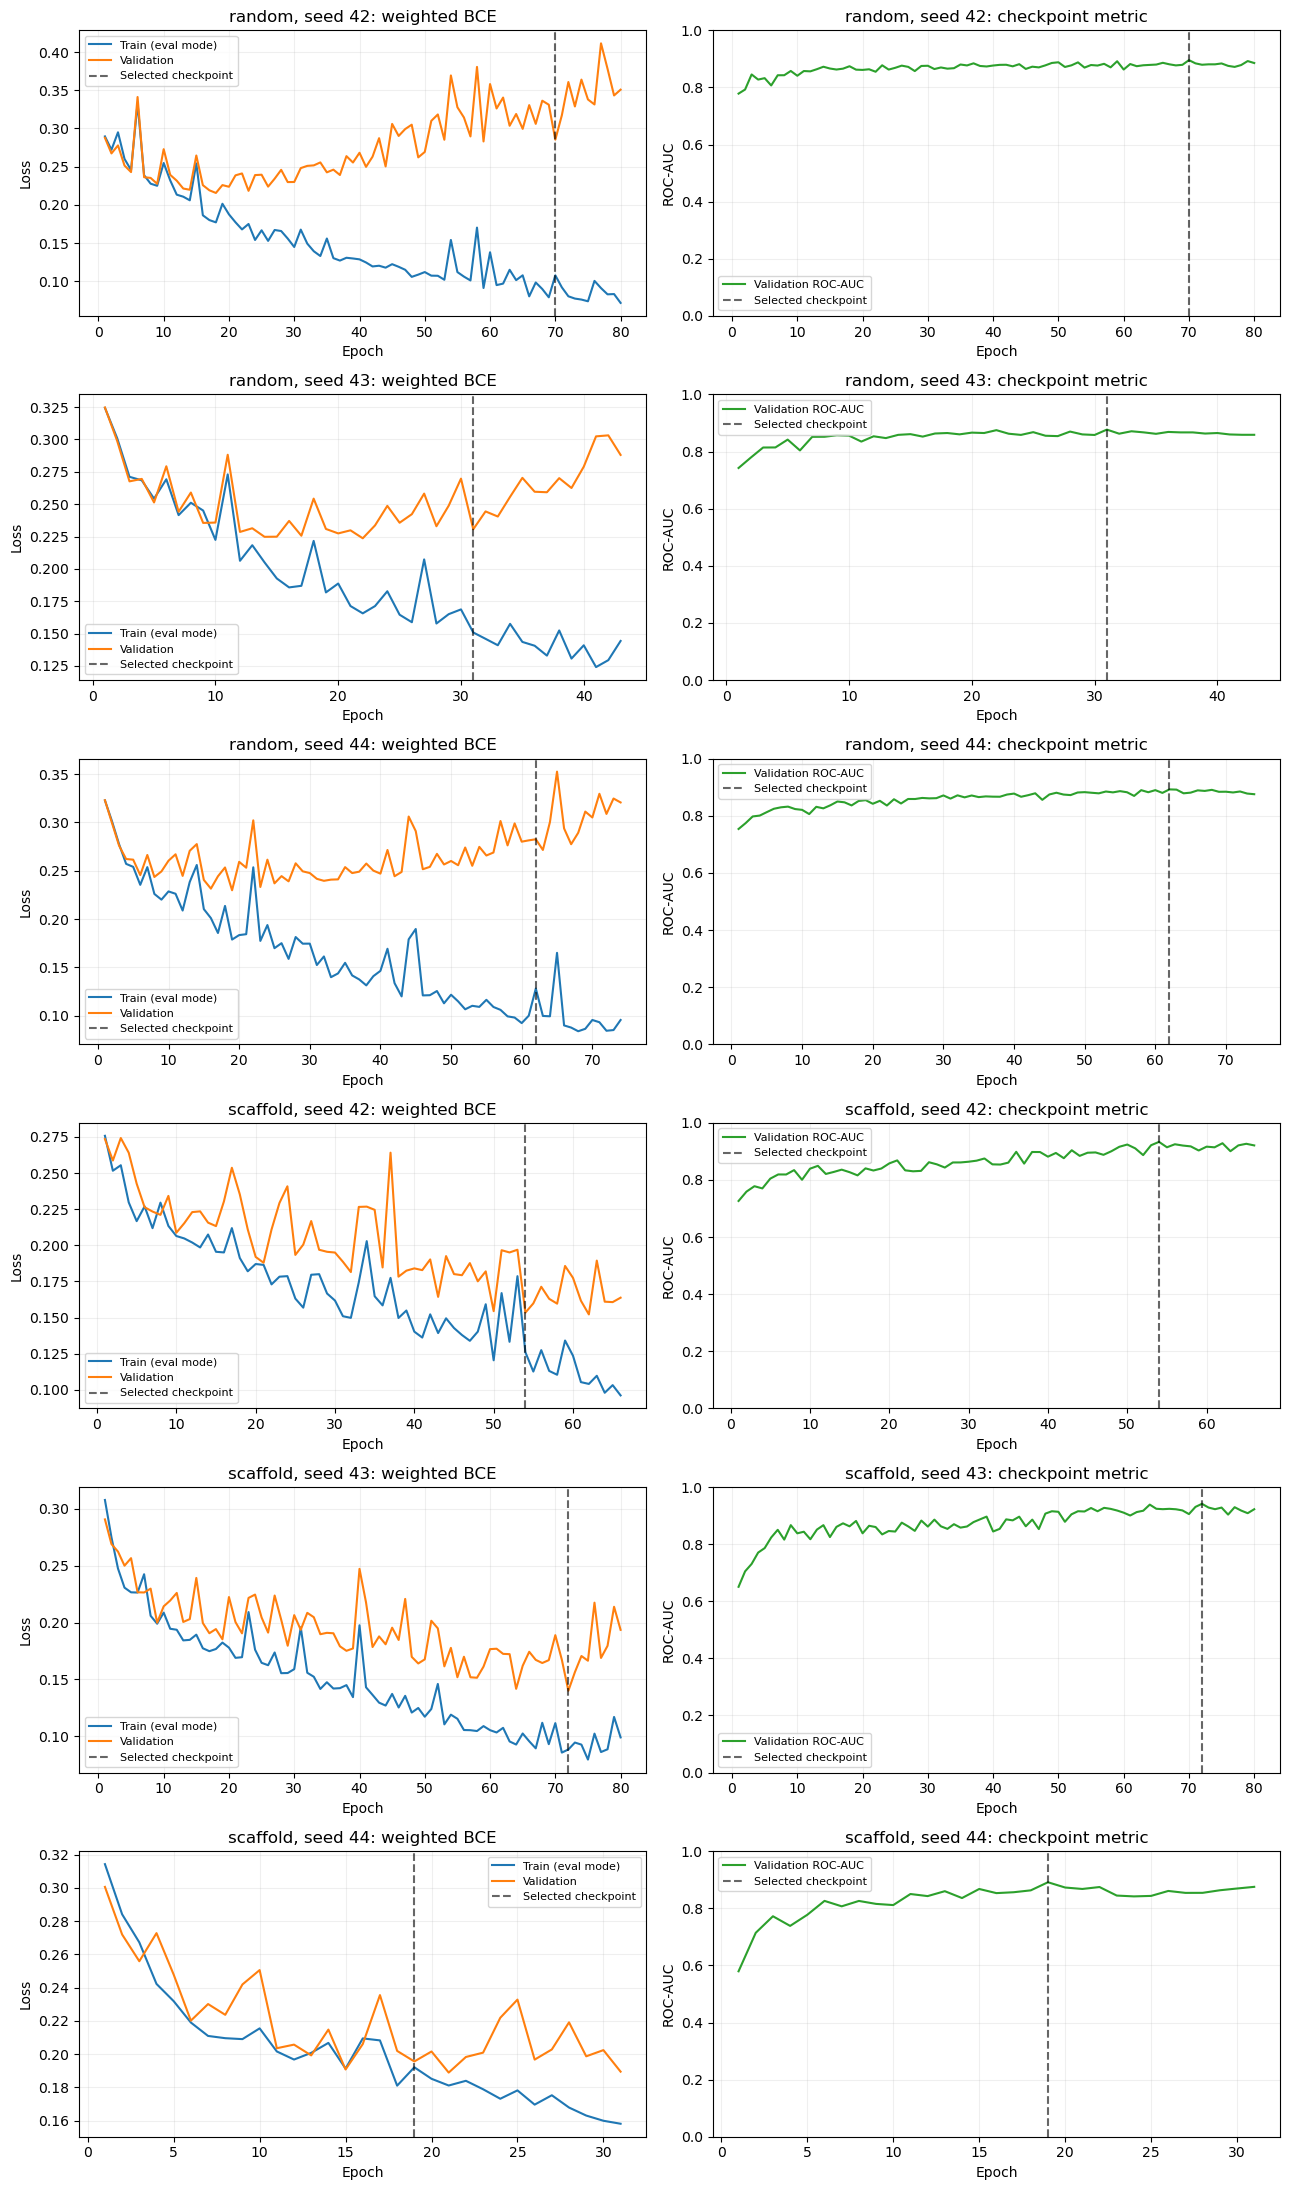

,split,seed,initial_train_loss,final_train_loss,val_loss_at_checkpoint,final_val_loss,checkpoint_val_auc,final_val_auc,largest_epoch_auc_change,post_checkpoint_overfit_signal
0,random,42,0.289632,0.071710,0.285358,0.350791,0.895619,0.885524,0.052825,True
1,random,43,0.324428,0.144343,0.230633,0.288065,0.877079,0.858857,0.047619,True
2,random,44,0.322880,0.095458,0.282617,0.320765,0.892381,0.875556,0.025397,True
3,scaffold,42,0.275736,0.096100,0.153385,0.163720,0.933298,0.920918,0.041267,True
4,scaffold,43,0.307898,0.098986,0.140044,0.193620,0.941101,0.922119,0.054172,False
5,scaffold,44,0.314276,0.158123,0.195595,0.189453,0.891131,0.875075,0.134829,False


In [ ]:
fig, axes = plt.subplots(6, 2, figsize=(13, 22))
for row_number, ((split_name, training_seed), run) in enumerate(gnn_runs.items()):
    history = run["history"]
    best_epoch = run["metadata"]["best_epoch"]
    ax_loss, ax_auc = axes[row_number]
    ax_loss.plot(history["epoch"], history["train_loss"], label="Train (eval mode)")
    ax_loss.plot(history["epoch"], history["val_loss"], label="Validation")
    ax_loss.set(title=f"{split_name}, seed {training_seed}: weighted BCE", xlabel="Epoch", ylabel="Loss")
    ax_auc.plot(history["epoch"], history["val_roc_auc"], color="tab:green", label="Validation ROC-AUC")
    ax_auc.set(title=f"{split_name}, seed {training_seed}: checkpoint metric",
               xlabel="Epoch", ylabel="ROC-AUC", ylim=(0, 1))
    for ax in (ax_loss, ax_auc):
        ax.axvline(best_epoch, color="black", linestyle="--", alpha=0.6, label="Selected checkpoint")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(GNN_OUTPUT / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Descriptive diagnostics use only training/validation curves not test results
curve_rows = []
for (split_name, training_seed), run in gnn_runs.items():
    h = run["history"]
    peak = h.loc[h["epoch"] == run["metadata"]["best_epoch"]].iloc[0]
    last = h.iloc[-1]
    curve_rows.append({
        "split": split_name, "seed": training_seed,
        "initial_train_loss": h.iloc[0]["train_loss"],
        "final_train_loss": last["train_loss"],
        "val_loss_at_checkpoint": peak["val_loss"], "final_val_loss": last["val_loss"],
        "checkpoint_val_auc": peak["val_roc_auc"], "final_val_auc": last["val_roc_auc"],
        "largest_epoch_auc_change": h["val_roc_auc"].diff().abs().max(),
        "post_checkpoint_overfit_signal": bool(last["train_loss"] < peak["train_loss"]
                                               and last["val_loss"] > peak["val_loss"]),
    })
curve_diagnostics = pd.DataFrame(curve_rows)
display(curve_diagnostics)


## F. Final test evaluation and comparison

In [ ]:
FINAL_OUTPUT = Path("artifacts/final_evaluation")
FINAL_OUTPUT.mkdir(parents=True, exist_ok=True)
METRIC_COLUMNS = ["roc_auc", "pr_auc", "accuracy", "sensitivity", "specificity", "f1"]

@torch.no_grad()
def predict_gnn_test(model, indices):
    model.eval()
    probabilities, targets = [], []
    for batch in make_gnn_loader(indices):
        batch = batch.to(DEVICE)
        logits = model(batch)
        assert logits.shape == (batch.num_graphs,)
        probabilities.append(torch.sigmoid(logits).cpu().numpy())
        targets.append(batch.y.view(-1).cpu().numpy())
    return np.concatenate(targets).astype(int), np.concatenate(probabilities)

def final_metrics(y_true, probability, threshold):
    assert np.unique(y_true).size == 2, "Both classes required for final ROC-AUC"
    assert np.isfinite(probability).all() and np.all((probability >= 0) & (probability <= 1))
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    precision, recall, _ = precision_recall_curve(y_true, probability)
    return {
        "roc_auc": roc_auc_score(y_true, probability), "pr_auc": auc(recall, precision),
        "accuracy": accuracy_score(y_true, prediction),
        "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
        "f1": f1_score(y_true, prediction, zero_division=0),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

# Fingerprint the frozen evaluation configuration before reusing memory predictions
def frozen_evaluation_signature():
    digest = hashlib.sha256()
    for split_name, frozen in sorted(baseline_models.items()):
        digest.update(f"LR:{split_name}:{frozen['threshold']}".encode())
        for array in (frozen["test_idx"], frozen["model"].coef_, frozen["model"].intercept_):
            digest.update(np.asarray(array).tobytes())
    for (split_name, seed), run in sorted(gnn_runs.items()):
        digest.update(f"GINE:{split_name}:{seed}:{run['threshold']}".encode())
        digest.update(np.asarray(run["test_idx"]).tobytes())
        for name, tensor in sorted(run["model"].state_dict().items()):
            digest.update(name.encode())
            digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    digest.update("\n".join(clean_df["canon"]).encode())
    return digest.hexdigest()

current_evaluation_signature = frozen_evaluation_signature()

if "final_test_predictions" not in globals():
    final_test_predictions = {}
    for split_name, frozen in baseline_models.items():
        indices = frozen["test_idx"]
        assert np.array_equal(indices, baseline_splits[split_name]["test"])
        probability = frozen["model"].predict_proba(X_fp[indices])[:, 1]
        final_test_predictions[("Morgan + LR", split_name, SEED)] = {
            "indices": indices.copy(), "y_true": y_fp[indices].copy(),
            "probability": probability, "threshold": frozen["threshold"],
        }
        joblib.dump(frozen, FINAL_OUTPUT / f"baseline_{split_name}.joblib")
    for (split_name, training_seed), run in gnn_runs.items():
        indices = run["test_idx"]
        assert np.array_equal(indices, baseline_splits[split_name]["test"])
        y_true, probability = predict_gnn_test(run["model"], indices)
        assert np.array_equal(y_true, y_fp[indices])
        final_test_predictions[("GINE", split_name, training_seed)] = {
            "indices": indices.copy(), "y_true": y_true,
            "probability": probability, "threshold": run["threshold"],
        }
    final_evaluation_signature = current_evaluation_signature
    print("Final test predictions computed with frozen models and thresholds.")
else:
    assert globals().get("final_evaluation_signature") == current_evaluation_signature, (
        "Cached test predictions belong to different models/splits/thresholds. "
        "Do not mix runs or tune settings using test results."
    )
    print("Reusing existing final test predictions; no model is re-evaluated.")

expected_keys = {("Morgan + LR", split_name, SEED) for split_name in baseline_splits}
expected_keys |= {("GINE", split_name, seed) for split_name in baseline_splits for seed in GNN_SEEDS}
assert set(final_test_predictions) == expected_keys
final_rows, prediction_frames = [], []
for (model_name, split_name, training_seed), result in final_test_predictions.items():
    indices = result["indices"]
    assert np.array_equal(indices, baseline_splits[split_name]["test"])
    assert np.array_equal(result["y_true"], y_fp[indices])
    assert len(result["probability"]) == len(indices)
    frozen_threshold = (baseline_models[split_name]["threshold"] if model_name == "Morgan + LR"
                        else gnn_runs[(split_name, training_seed)]["threshold"])
    assert result["threshold"] == frozen_threshold
    final_rows.append({
        "model": model_name, "split": split_name, "seed": training_seed,
        "threshold": result["threshold"], "n_test": len(indices),
        **final_metrics(result["y_true"], result["probability"], result["threshold"]),
    })
    prediction_frames.append(pd.DataFrame({
        "model": model_name, "split": split_name, "seed": training_seed,
        "clean_position": indices,
        "canonical_smiles": clean_df["canon"].iloc[indices].to_numpy(),
        "y_true": result["y_true"], "probability": result["probability"],
        "threshold": result["threshold"],
        "y_pred": (result["probability"] >= result["threshold"]).astype(int),
    }))
final_test_results = pd.DataFrame(final_rows)
final_test_results.to_csv(FINAL_OUTPUT / "test_metrics.csv", index=False)
pd.concat(prediction_frames, ignore_index=True).to_csv(FINAL_OUTPUT / "test_predictions.csv", index=False)

comparison_rows = []
for split_name in baseline_splits:
    subset = final_test_results[final_test_results["split"] == split_name]
    for _, row in subset.iterrows():
        comparison_rows.append({
            "model": row["model"], "split": split_name, "seed": str(row["seed"]),
            **{col: f"{row[col]:.4f}" for col in ["threshold"] + METRIC_COLUMNS},
        })
    gnn_subset = subset[subset["model"] == "GINE"]
    comparison_rows.append({
        "model": "GINE mean ± SD", "split": split_name, "seed": "42, 43, 44",
        **{col: f"{gnn_subset[col].mean():.4f} ± {gnn_subset[col].std(ddof=1):.4f}"
           for col in ["threshold"] + METRIC_COLUMNS},
    })
final_comparison = pd.DataFrame(comparison_rows)
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(final_comparison)
final_comparison.to_csv(FINAL_OUTPUT / "comparison_table.csv", index=False)
print("All final metrics and prediction records saved to", FINAL_OUTPUT)


Final test predictions computed with frozen models and thresholds.


,model,split,seed,threshold,roc_auc,pr_auc,accuracy,sensitivity,specificity,f1
0,Morgan + LR,random,42,0.3200,0.8917,0.9540,0.8746,0.9600,0.6000,0.9211
1,GINE,random,42,0.0800,0.9116,0.9658,0.8915,0.9556,0.6857,0.9307
2,GINE,random,43,0.1600,0.8955,0.9606,0.8644,0.9556,0.5714,0.9149
3,GINE,random,44,0.0800,0.8819,0.9504,0.8508,0.9244,0.6143,0.9043
4,GINE mean ± SD,random,"42, 43, 44",0.1067 ± 0.0462,0.8963 ± 0.0149,0.9589 ± 0.0078,0.8689 ± 0.0207,0.9452 ± 0.0180,0.6238 ± 0.0577,0.9167 ± 0.0133
5,Morgan + LR,scaffold,42,0.3100,0.8275,0.9003,0.7736,0.9353,0.4316,0.8488
6,GINE,scaffold,42,0.0800,0.8633,0.9283,0.8007,0.9652,0.4526,0.8680
7,GINE,scaffold,43,0.0800,0.8346,0.9118,0.8142,0.9851,0.4526,0.8780
8,GINE,scaffold,44,0.1200,0.8089,0.9024,0.7432,0.8706,0.4737,0.8216
9,GINE mean ± SD,scaffold,"42, 43, 44",0.0933 ± 0.0231,0.8356 ± 0.0272,0.9142 ± 0.0131,0.7860 ± 0.0377,0.9403 ± 0.0611,0.4596 ± 0.0122,0.8559 ± 0.0301


All final metrics and prediction records saved to artifacts/final_evaluation


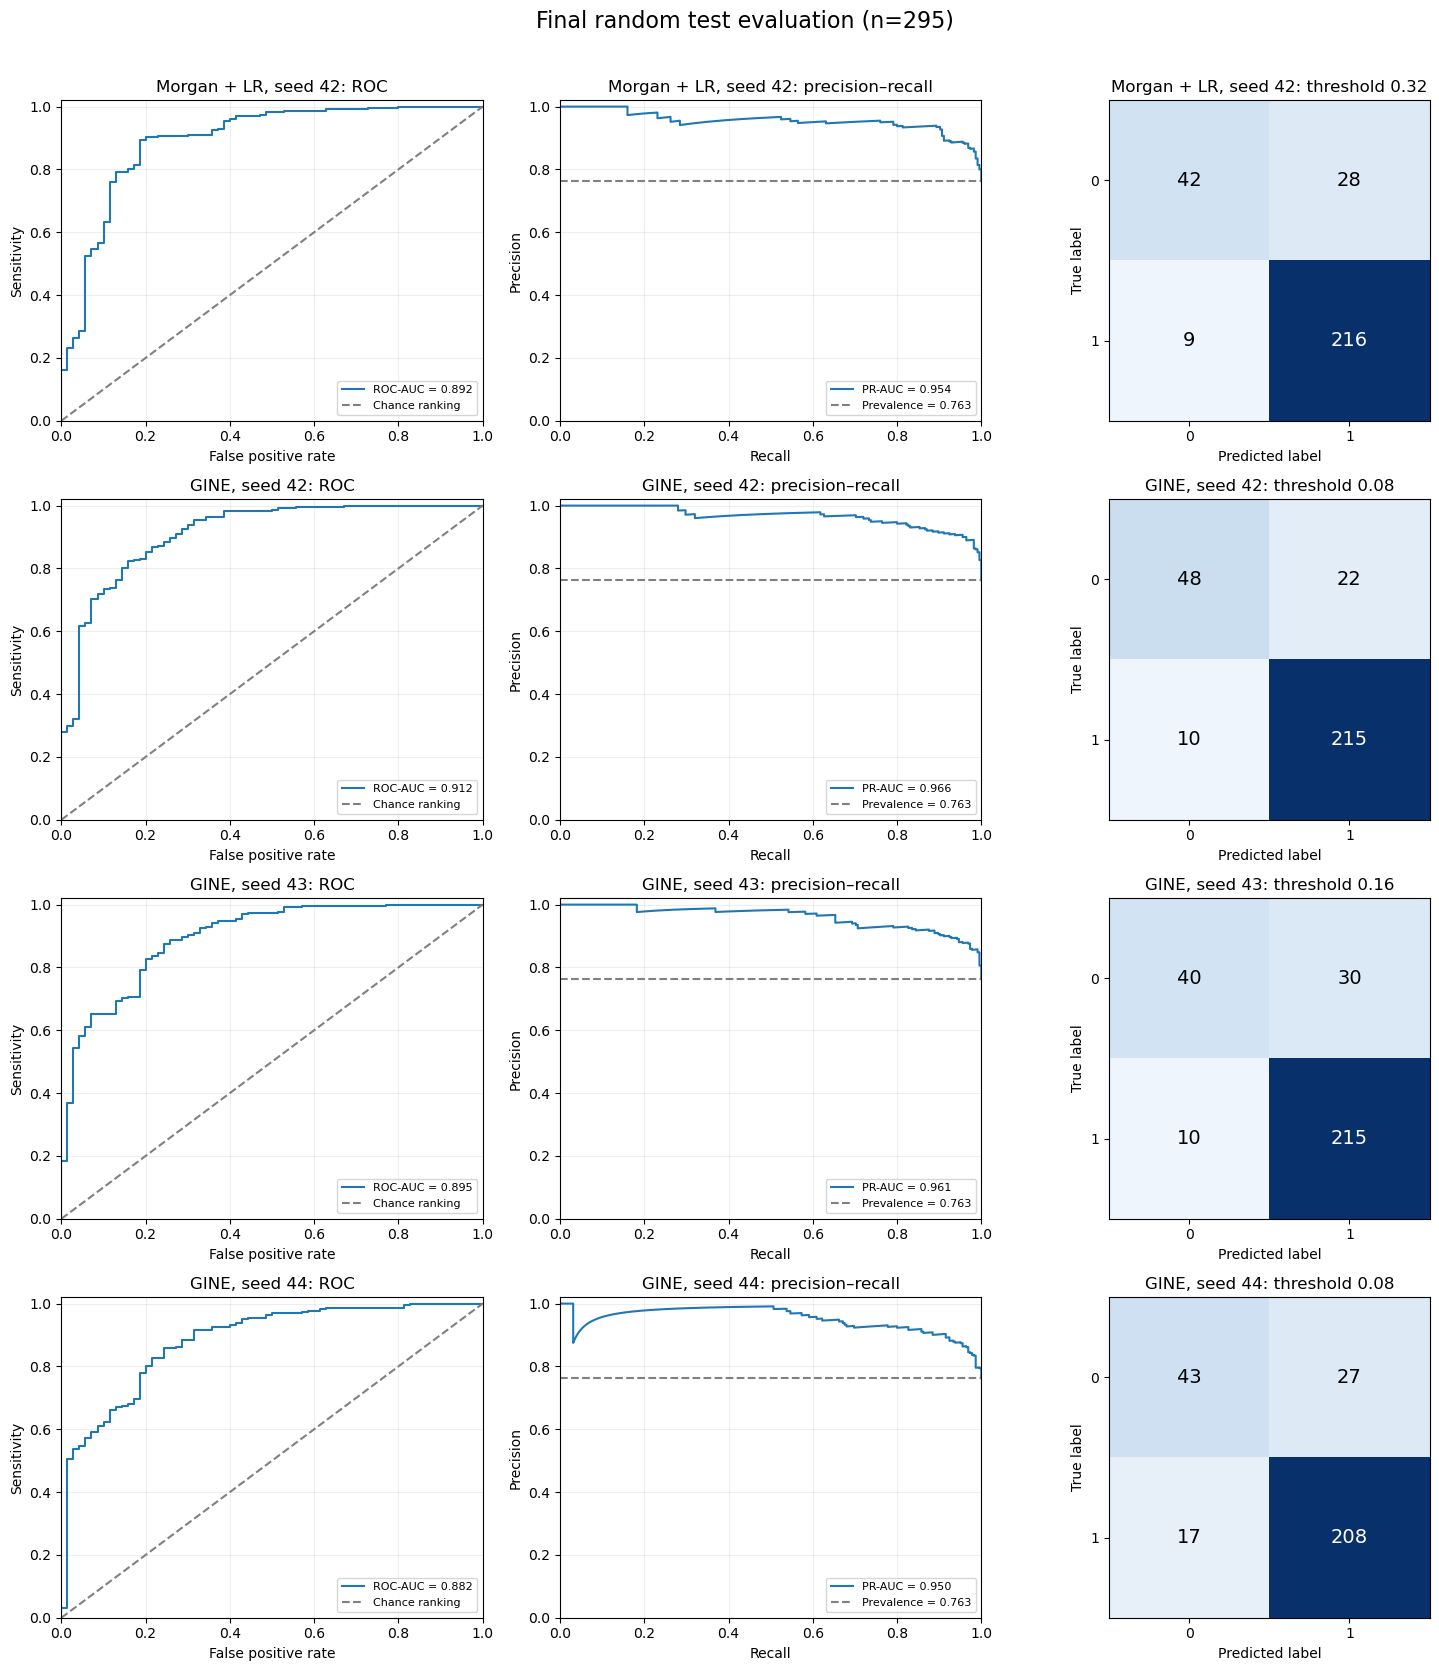

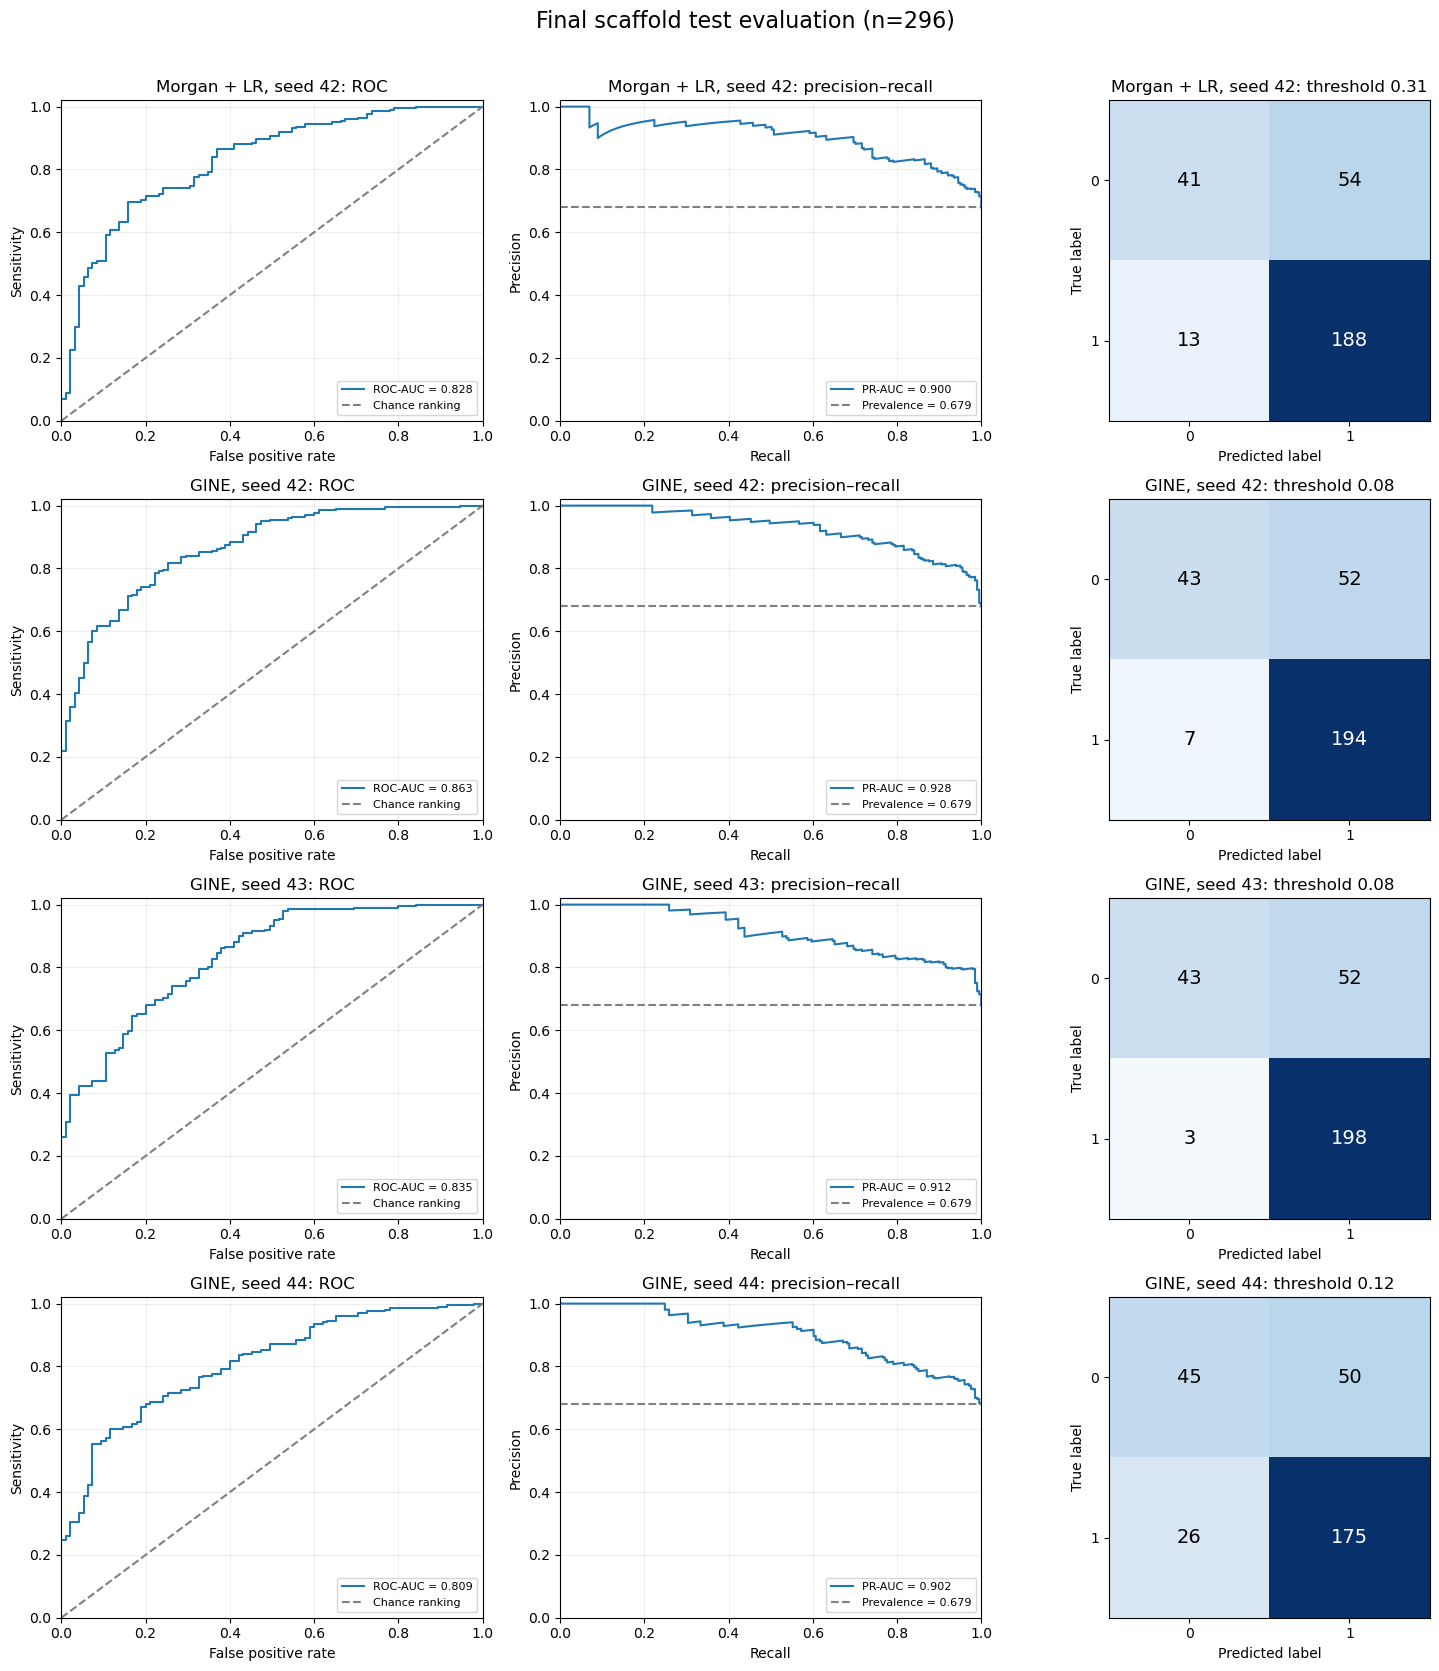

In [ ]:
# One row per final model,  ROC, PR, and confusion matrix from the same stored predictions
for split_name in baseline_splits:
    keys = [("Morgan + LR", split_name, SEED)] + [
        ("GINE", split_name, seed) for seed in GNN_SEEDS
    ]
    fig, axes = plt.subplots(len(keys), 3, figsize=(15, 17))
    for row_number, key in enumerate(keys):
        model_name, _, training_seed = key
        result = final_test_predictions[key]
        y_true, probability, threshold = result["y_true"], result["probability"], result["threshold"]
        metrics = final_metrics(y_true, probability, threshold)
        fpr, tpr, _ = roc_curve(y_true, probability)
        precision, recall, _ = precision_recall_curve(y_true, probability)
        ax_roc, ax_pr, ax_cm = axes[row_number]
        label = f"{model_name}, seed {training_seed}"
        ax_roc.plot(fpr, tpr, label=f"ROC-AUC = {metrics['roc_auc']:.3f}")
        ax_roc.plot([0, 1], [0, 1], "--", color="gray", label="Chance ranking")
        ax_roc.set(title=f"{label}: ROC", xlabel="False positive rate", ylabel="Sensitivity",
                   xlim=(0, 1), ylim=(0, 1.02))
        ax_pr.plot(recall, precision, label=f"PR-AUC = {metrics['pr_auc']:.3f}")
        ax_pr.axhline(y_true.mean(), linestyle="--", color="gray",
                     label=f"Prevalence = {y_true.mean():.3f}")
        ax_pr.set(title=f"{label}: precision–recall", xlabel="Recall", ylabel="Precision",
                  xlim=(0, 1), ylim=(0, 1.02))
        for ax in (ax_roc, ax_pr):
            ax.legend(loc="lower right", fontsize=8)
            ax.grid(alpha=0.2)
        cm = confusion_matrix(y_true, probability >= threshold, labels=[0, 1])
        ax_cm.imshow(cm, cmap="Blues", vmin=0, vmax=max(1, cm.max()))
        for (i, j), value in np.ndenumerate(cm):
            ax_cm.text(j, i, str(value), ha="center", va="center",
                       color="white" if value > cm.max() / 2 else "black", fontsize=14)
        ax_cm.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["0", "1"], yticklabels=["0", "1"],
                  xlabel="Predicted label", ylabel="True label",
                  title=f"{label}: threshold {threshold:.2f}")
    fig.suptitle(f"Final {split_name} test evaluation (n={len(y_true)})", fontsize=16)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(FINAL_OUTPUT / f"{split_name}_test_curves.png", dpi=150, bbox_inches="tight")
    plt.show()


## G. Error and similarity analysis

### Selection and similarity method

In [ ]:
ERROR_OUTPUT = Path("artifacts/error_analysis")
ERROR_OUTPUT.mkdir(parents=True, exist_ok=True)
ERROR_SEED = GNN_SEEDS[0]
error_key = ("GINE", "scaffold", ERROR_SEED)
frozen_test = final_test_predictions[error_key]
error_threshold = frozen_test["threshold"]
error_frame = pd.DataFrame({
    "clean_position": frozen_test["indices"], "label": frozen_test["y_true"],
    "probability": frozen_test["probability"],
})
error_frame["prediction"] = (error_frame["probability"] >= error_threshold).astype(int)
fp_errors = error_frame[(error_frame["label"] == 0) & (error_frame["prediction"] == 1)]
fn_errors = error_frame[(error_frame["label"] == 1) & (error_frame["prediction"] == 0)]
print(f"Scaffold GINE seed {ERROR_SEED}: {len(fp_errors)} false positives, "
      f"{len(fn_errors)} false negatives; threshold={error_threshold:.2f}")
assert len(fp_errors) >= 2 and len(fn_errors) >= 2, "Insufficient errors for requested examples"
selected_errors = pd.concat([
    fp_errors.sort_values("clean_position").head(2).assign(error_type="False positive"),
    fn_errors.sort_values("clean_position").head(2).assign(error_type="False negative"),
], ignore_index=True)

training_positions = np.sort(np.asarray(scaf_train, dtype=int))
training_fingerprints = [fp_generator.GetFingerprint(clean_df["mol"].iloc[i])
                         for i in training_positions]
pair_records = []
for _, error in selected_errors.iterrows():
    error_position = int(error["clean_position"])
    fingerprint = fp_generator.GetFingerprint(clean_df["mol"].iloc[error_position])
    similarities = np.asarray(DataStructs.BulkTanimotoSimilarity(fingerprint, training_fingerprints))
    nearest_offset = int(np.argmax(similarities))
    nearest_position = int(training_positions[nearest_offset])
    assert error_position in set(scaf_test) and nearest_position in set(scaf_train)
    assert clean_df["canon"].iloc[error_position] != clean_df["canon"].iloc[nearest_position]
    assert clean_df["scaffold"].iloc[error_position] != clean_df["scaffold"].iloc[nearest_position]
    pair_records.append({
        "error_type": error["error_type"], "test_position": error_position,
        "test_smiles": clean_df["canon"].iloc[error_position],
        "test_label": int(error["label"]), "test_probability": float(error["probability"]),
        "test_prediction": int(error["prediction"]),
        "train_position": nearest_position,
        "train_smiles": clean_df["canon"].iloc[nearest_position],
        "train_label": int(y_fp[nearest_position]),
        "tanimoto": float(similarities[nearest_offset]),
        "threshold": float(error_threshold),
    })

# Predict only the selected training neighbors
neighbor_positions = np.array(sorted({r["train_position"] for r in pair_records}), dtype=int)
neighbor_loader = make_gnn_loader(neighbor_positions)
error_model = gnn_runs[("scaffold", ERROR_SEED)]["model"]
error_model.eval()
neighbor_probabilities = []
with torch.no_grad():
    for batch in neighbor_loader:
        batch = batch.to(DEVICE)
        neighbor_probabilities.extend(torch.sigmoid(error_model(batch)).cpu().numpy().tolist())
neighbor_lookup = dict(zip(neighbor_positions.tolist(), neighbor_probabilities))
for pair in pair_records:
    pair["train_probability"] = neighbor_lookup[pair["train_position"]]
    pair["train_prediction"] = int(pair["train_probability"] >= error_threshold)
error_pairs = pd.DataFrame(pair_records)
assert len(error_pairs) == 4 and error_pairs["tanimoto"].between(0, 1).all()
assert error_pairs["test_position"].is_unique
error_pairs.to_csv(ERROR_OUTPUT / "error_similarity_pairs.csv", index=False)
with pd.option_context("display.max_columns", None):
    display(error_pairs.drop(columns=["test_smiles", "train_smiles"]))
# Full SMILES are preserved in this separate table and the exported CSV
with pd.option_context("display.max_colwidth", None):
    display(error_pairs[["error_type", "test_position", "test_smiles", "train_position", "train_smiles"]])


Scaffold GINE seed 42: 52 false positives, 7 false negatives; threshold=0.08


,error_type,test_position,test_label,test_probability,test_prediction,train_position,train_label,tanimoto,threshold,train_probability,train_prediction
0,False positive,35,0,0.381477,1,942,1,0.300000,0.08,0.819938,1
1,False positive,100,0,0.463658,1,452,1,0.294118,0.08,0.622222,1
2,False negative,66,1,0.012525,0,350,1,0.627907,0.08,0.021893,0
3,False negative,284,1,0.028183,0,275,0,0.280899,0.08,0.006336,0


,error_type,test_position,test_smiles,train_position,train_smiles
0,False positive,35,CN(C)c1cc(-c2nc(N)n[nH]2)ccn1,942,CN(C)c1cnccn1
1,False positive,100,CCCCc1oc2ccccc2c1C(=O)c1cc(I)c(OCCN(CC)CC)c(I)c1,452,CCN(CC)CCOC(=O)C(O)(c1ccccc1)c1ccccc1.[Cl-].[H+]
2,False negative,66,CO/N=C(\C(=O)N[C@H]1C(=O)N2C(C(=O)[O-])=C(COC(C)=O)CS[C@@H]12)c1csc(N)n1.[Na+],350,CC(C)(O/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)[O-])=C(C[n+]3ccccc3)CS[C@H]12)c1csc(N)n1)C(=O)O
3,False negative,284,CN(C)c1ccc(O)c2c1C[C@H]1C[C@H]3[C@H](N(C)C)C(O)=C(C(N)=O)C(=O)[C@@]3(O)C(O)=C1C2=O,275,C=C1c2c(Cl)ccc(O)c2C(O)=C2C(=O)C3(O)C(=O)/C(=C(/N)O)C(=O)C(N(C)C)C3C(O)C12


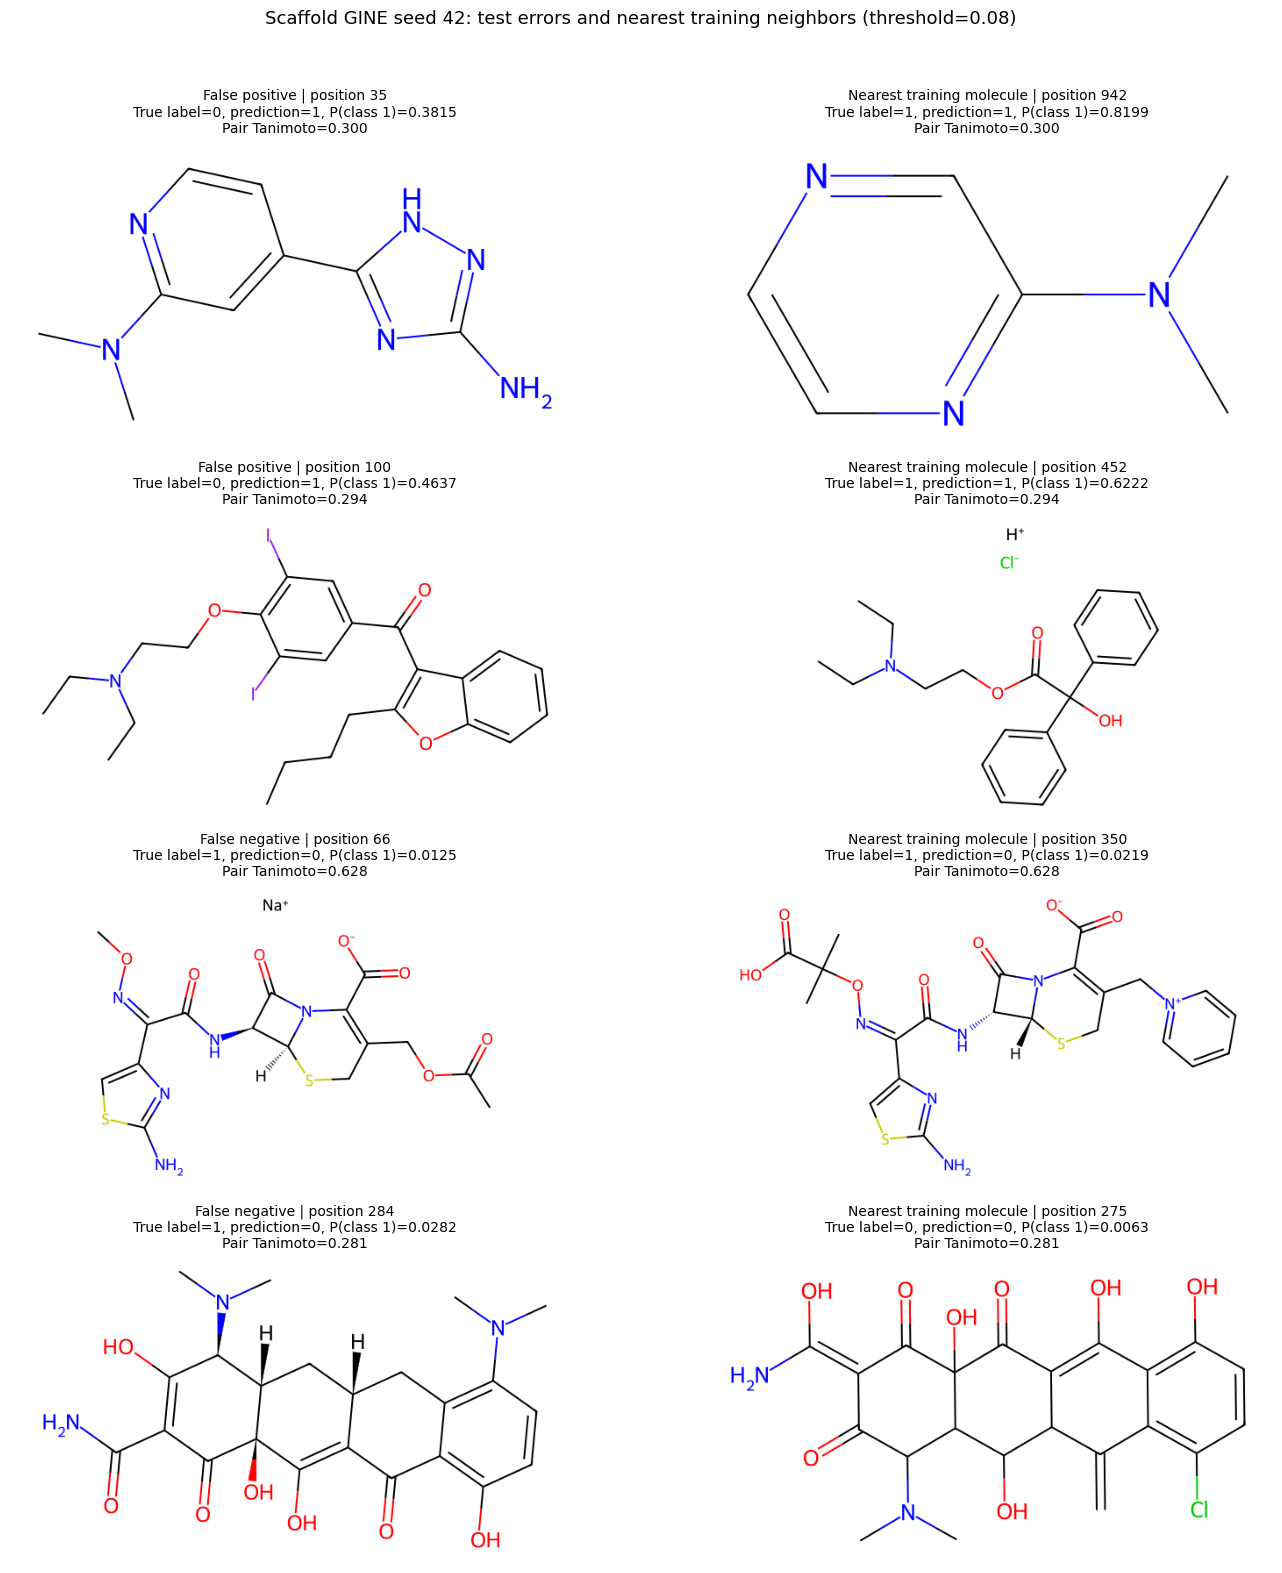

In [49]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for row_number, pair in error_pairs.iterrows():
    for col, role in enumerate(("test", "train")):
        position = int(pair[f"{role}_position"])
        mol = clean_df["mol"].iloc[position]
        ax = axes[row_number, col]
        ax.imshow(Draw.MolToImage(mol, size=(650, 350)))
        ax.axis("off")
        description = pair["error_type"] if role == "test" else "Nearest training molecule"
        ax.set_title(
            f"{description} | position {position}\n"
            f"True label={int(pair[f'{role}_label'])}, prediction={int(pair[f'{role}_prediction'])}, "
            f"P(class 1)={pair[f'{role}_probability']:.4f}\n"
            f"Pair Tanimoto={pair['tanimoto']:.3f}", fontsize=10,
        )
fig.suptitle(f"Scaffold GINE seed {ERROR_SEED}: test errors and nearest training neighbors "
             f"(threshold={error_threshold:.2f})", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(ERROR_OUTPUT / "error_similarity_pairs.png", dpi=150, bbox_inches="tight")
plt.show()
